# Optimize every vertex independently

Give **each vertex of each polygon its own x and y design parameters**.
This 3×3 square grid has 9 polygons × 4 corners × 2 coordinates = **72 independent
scalar offsets**. This includes every corner of the clamped top and bottom polygons.

We fit a synthetic stress–strain curve with fixed spring constants. The workflow
is geometry → boundary conditions → shape map and initialization → potential and
equilibrium solver → target and restrictions → optimization. Relevant lines have
comments so you can change each part.

Install with `python -m pip install -e ".[notebook]"` from the repository root,
then select that environment as the kernel. The complete runnable Python version
is [optimize_all_vertices.py](optimize_all_vertices.py).

In [1]:
from pathlib import Path
from types import SimpleNamespace
import sys

import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from rotating_polygons import (
    square_grid,
    compression_boundary,
    initialize,
    PotentialParameters,
    make_potential,
    QuasistaticOptions,
    make_quasistatic_solver,
    make_stress_measurement,
    stress_curve_loss,
    make_shape_constraint,
    minimize_design,
)

jax.config.update("jax_enable_x64", True)  # Set precision before creating JAX arrays.
%matplotlib inline

# Support launching Jupyter from either the repository root or examples/.
example_directory = Path.cwd() / "examples" if (Path.cwd() / "examples").is_dir() else Path.cwd()
if str(example_directory) not in sys.path:
    sys.path.insert(0, str(example_directory))
# Helper imports follow the path setup; the calculation is written below.
from draw_vertex_design import plot_setup  # noqa: E402
from optimize_all_vertices import plot_result  # noqa: E402

## 1. Define the square grid and its mechanical supports

Polygon IDs increase left to right, then bottom to top. Each polygon's four local
vertices are ordered **right, up, left, down**. The local origin is its fixed
reference center; it is not recomputed as the centroid when the shape changes.

At each compression step, the bottom centers and angles stay fixed. The top
centers move down by $\epsilon H$ while their x coordinates and angles stay fixed.
The middle row can translate and rotate. This gives **9 free mechanical coordinates**.
They are distinct from the **72 design coordinates** the outer optimizer changes.

In [2]:
nx, ny = 3, 3  # Change these to choose a different grid size.
geometry = square_grid(
    nx, ny, spacing=1.0, hinge_gap=0.2
)  # Generate polygons and hinge connections.
boundary = compression_boundary(geometry)  # Clamp both grips; drive only the top y coordinates.
parameter_shape = (geometry.n_polygons, 4, 2)  # Axes: polygon ID, corner ID, local x/y.
print("Design tensor:", parameter_shape, "=", np.prod(parameter_shape), "scalar variables")
print("Free mechanical coordinates:", boundary.free_indices.size)
print("Fixed mask (columns x, y, angle):\n", np.asarray(boundary.fixed_mask, dtype=int))
print("Reference grip height / width:", boundary.height, boundary.width)

Design tensor: (9, 4, 2) = 72 scalar variables
Free mechanical coordinates: 9
Fixed mask (columns x, y, angle):
 [[1 1 1]
 [1 1 1]
 [1 1 1]
 [0 0 0]
 [0 0 0]
 [0 0 0]
 [1 1 1]
 [1 1 1]
 [1 1 1]]
Reference grip height / width: 2.0 2.8


## 2. Read the setup drawing

The drawing shows the reference grid and a magnified illustrative change to one
polygon. Its arrows are shape-design offsets, specified in the polygon's local
frame. Once a candidate shape has been chosen, its world vertices are
$\mathbf{x}_{p,c}=\mathbf{q}_{p,xy}+R(\theta_p)(\mathbf{v}^{0}_{p,c}+
\boldsymbol{\delta}_{p,c})$.

During a simulation, only the center $\mathbf{q}_{p,xy}$ and angle $\theta_p$
can move: each polygon stays rigid. Between simulations, the design optimizer
changes $\boldsymbol{\delta}_{p,c}$ and therefore the reference polygon shapes.
Fixing a grip's mechanical coordinates does **not** fix its design offsets.

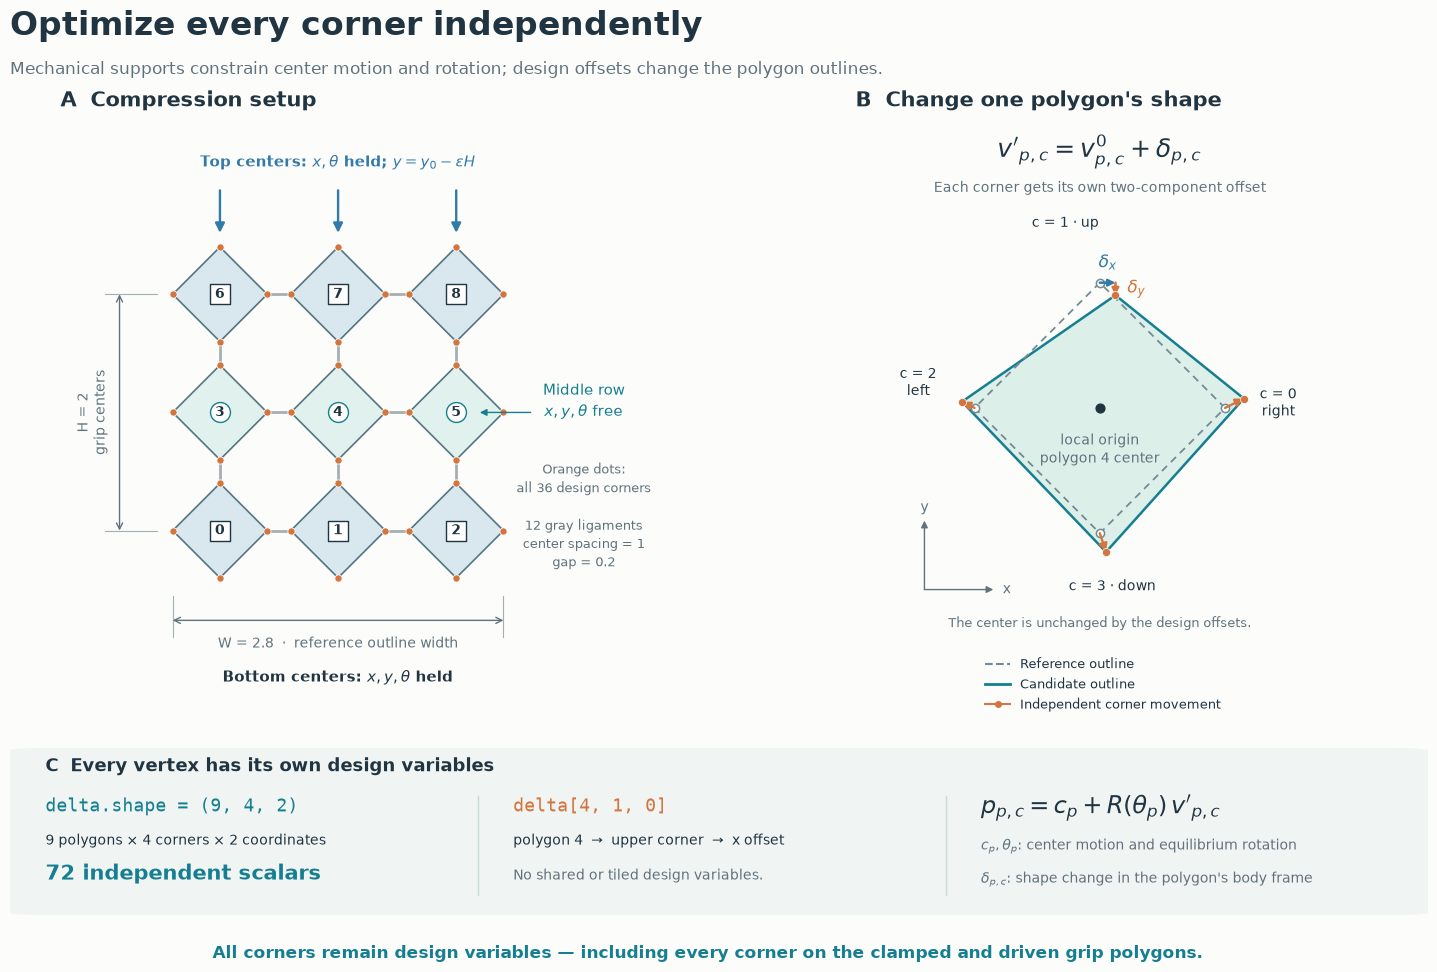

In [3]:
setup_figure = plot_setup()  # Default 3×3 setup with annotated independent vertex offsets.
plt.show()

## 3. Map all 72 variables directly to local vertices

`offsets[p, c, 0]` moves corner `c` of polygon `p` along local x.
`offsets[p, c, 1]` moves only that corner along local y.
For example, `offsets[4, 1, 0]` moves polygon 4's upper corner horizontally.

The `reshape` below only changes the array layout to the library's `(36, 2)`
vertex format. It introduces no sharing between polygons or corners.
Zero offsets reproduce the square template.

In [4]:
def vertices_from_parameters(offsets):
    return geometry.vertices + offsets.reshape((-1, 2))  # One offset per vertex coordinate.


def initialize_design(offsets):
    vertices = vertices_from_parameters(offsets)  # Candidate polygon shapes in their local frames.
    return initialize(geometry, vertices)  # Recompute all hinge rest lengths and angles.


# Demonstrate the indexing with ONE changed scalar; this is not the optimizer's initial guess.
zero_offsets = jnp.zeros(parameter_shape)
one_vertex_demo = zero_offsets.at[4, 1, 0].set(0.04)  # Middle polygon, upper corner, x only.
change = vertices_from_parameters(one_vertex_demo) - vertices_from_parameters(zero_offsets)
changed_entries = np.argwhere(np.abs(np.asarray(change)) > 1e-12)
np.testing.assert_array_equal(changed_entries, [[4 * 4 + 1, 0]])  # Exactly one coordinate changed.
print("Changed (global vertex ID, coordinate):", changed_entries.tolist())

# Each entry gets its own reproducible small perturbation, breaking perfect symmetry.
initial_rng = np.random.default_rng(2027)
initial_parameters = jnp.asarray(initial_rng.uniform(-0.003, 0.003, parameter_shape))

Changed (global vertex ID, coordinate): [[17, 0]]


## 4. Choose material coefficients, strain steps, and the inner solver

All spring coefficients below stay fixed while the vertices change. The
finite-length hinge energy includes stretching, endpoint-angle shear, bending,
and angular contact. See [the mechanical model](../docs/model.md) for the equations.

The **inner BFGS solve** finds equilibrium positions and angles at each strain.
Its `max_iterations` and `tolerance` do not select the design variables or control
the outer design optimizer.

Every candidate is initialized afresh inside the objective. Reusing the initial
hinge rest lengths after changing the vertices would introduce unintended prestress.
Nominal stress always uses the original width and thickness, even when the outline changes.

In [5]:
coefficients = PotentialParameters(
    stretching=1.0,
    shearing=0.1,
    bending=0.02,
    contact=40.0,
)  # Fixed material constants for this shape-design study.
potential = make_potential(geometry, coefficients, model="finite_hinge")
solver_options = QuasistaticOptions(
    method="bfgs",
    tolerance=1e-9,
    max_iterations=750,
)  # Force/torque residual tolerance and iteration limit for each equilibrium.
simulate = make_quasistatic_solver(geometry, boundary, potential, solver_options)  # Build once.
strains = jnp.linspace(0.0, 0.04, 7)  # Seven absolute compression strains, up to 4%.
measure_stress = make_stress_measurement(potential, boundary, thickness=1.0)

## 5. Create the target stress–strain curve

For a reproducible example, another heterogeneous grid generates the observations.
Its corners have different offsets. The optimizer receives only the target stress
samples, its own initial guess, and the restrictions; it is not given the target
offsets as a desired geometry.

Replace `target_stress` with your desired or measured values on the same strain grid
and in the same nominal-stress units. A single curve cannot uniquely identify this
many vertex coordinates; the task is to match the response.

In [6]:
target_rng = np.random.default_rng(2026)  # Separate seed from the optimizer's initial guess.
target_parameters = jnp.asarray(target_rng.uniform(-0.018, 0.018, parameter_shape))
target_parameters = target_parameters.at[:, 1, 0].add(
    0.03
)  # Add an upper-corner skew to the target.
target_reference = initialize_design(target_parameters)
target_solution = simulate(target_reference, strains).check_convergence()  # Check all equilibria.
target_stress = measure_stress(target_solution.states, target_reference)

curve_loss = stress_curve_loss(
    simulate,
    initialize_design,
    measure_stress,
    strains,
    target_stress,
)  # Mean squared stress error normalized by max(abs(target_stress)) squared.
print("Synthetic target stress:", np.asarray(target_stress))

Synthetic target stress: [2.83406668e-17 6.87748827e-03 1.37055727e-02 2.04716159e-02
 2.71575359e-02 3.37338548e-02 4.01385228e-02]


## 6. Bound each coordinate and restrict the reference geometry

All 72 scalar offsets have bounds of ±0.06 in geometry length units. Bounds are
flattened in polygon, corner, coordinate order: x then y for each corner.
The returned optimum is restored to the original `(9, 4, 2)` tensor.

Minimum edge length, positive corner sine, and minimum hinge length keep the
reference shapes usable. Constraint functions return margins that must be
nonnegative. These are reference-geometry restrictions, not general collision
checks for the full compressed trajectory.

In [7]:
offset_bound = 0.06  # Same permitted range, but a separate variable for EVERY coordinate.
bounds = [(-offset_bound, offset_bound)] * initial_parameters.size
constraint = make_shape_constraint(
    geometry,
    vertices_from_parameters,
    min_edge_length=0.2,  # Avoid vanishing polygon edges.
    min_corner_sine=0.25,  # Keep convex corners away from a flat or inverted angle.
    min_ligament_length=0.08,  # Keep finite-length connecting hinges away from zero length.
)
assert np.min(np.asarray(constraint(initial_parameters))) >= 0  # Initial design is feasible.
assert np.min(np.asarray(constraint(target_parameters))) >= 0  # Synthetic target is feasible.

## 7. Choose the objective and regularization

We minimize normalized stress-curve error plus a small penalty on the squared
offsets. The penalty favors changes near the original square template while
leaving every coordinate independent. Set `regularization_weight = 0.0` for
stress matching alone, or increase it to favor smaller shape changes.

Some outer corners are not hinge endpoints; some hinges within a clamped grip
do not deform under this loading. Their coordinates can have little or no effect
on the stress curve when contact is inactive. They still affect geometry constraints
and remain optimization variables. The penalty gives such directions a preference
for smaller offsets; it does not make a single stress curve identify every corner.

In [8]:
regularization_weight = 1e-4  # Small dimensionless weight; this is a design choice.


def loss(offsets):
    penalty = regularization_weight * jnp.mean((offsets / offset_bound) ** 2)
    return curve_loss(offsets) + penalty  # Scalar objective for the OUTER optimizer.


initial_curve_error = float(curve_loss(initial_parameters))  # Report fit error separately.
value, gradient = jax.jit(jax.value_and_grad(loss))(initial_parameters)
assert gradient.shape == parameter_shape and np.all(np.isfinite(np.asarray(gradient)))
print("Initial total cost:", float(value))
print("Gradient tensor:", gradient.shape, "— one derivative per design coordinate")

Initial total cost: 0.0012175296139198097
Gradient tensor: (9, 4, 2) — one derivative per design coordinate


## 8. Optimize the full tensor

The **outer SLSQP optimizer** changes all the vertex offsets. JAX differentiates
through the reference initialization and equilibrium response. Here, `maxiter`
and `tol` control the design optimizer; they are separate from the BFGS settings.
The first call includes JAX compilation.

In [9]:
result = minimize_design(
    loss,
    initial_parameters,  # The entire tensor is active: 72 scalar design variables.
    bounds=bounds,
    constraints=[constraint],
    maxiter=100,  # Outer design iterations.
    tol=1e-10,  # SLSQP termination and final feasibility tolerance.
)
if not result.success or not result.feasible:
    raise RuntimeError(result.message)  # Do not silently present a failed design as an optimum.

optimized_offsets = result.parameters  # Same (polygon, corner, x/y) layout as the initial guess.
optimized_reference = initialize_design(optimized_offsets)
optimized_solution = simulate(optimized_reference, strains).check_convergence()
final_curve_error = float(curve_loss(optimized_offsets))
assert final_curve_error < initial_curve_error and result.fun < result.initial_loss
assert np.min(np.asarray(constraint(optimized_offsets))) >= -1e-10
print("Optimized parameter shape:", optimized_offsets.shape)
print(f"Stress-curve MSE: {initial_curve_error:.8g} -> {final_curve_error:.8g}")
print(f"Total cost: {result.initial_loss:.8g} -> {result.fun:.8g}")
print("Maximum constraint violation:", result.max_constraint_violation)
print("Maximum equilibrium residual:", float(jnp.max(optimized_solution.residuals)))

Optimized parameter shape: (9, 4, 2)
Stress-curve MSE: 0.0012174394 -> 2.2281194e-08
Total cost: 0.0012175296 -> 7.0275133e-07
Maximum constraint violation: 0.0
Maximum equilibrium residual: 7.483404176520251e-10


## 9. Inspect the curve, shapes, and every individual offset

The initial and optimized reference-shape panels use identical center positions,
angles, and axis limits. Their differences therefore show design changes.
The final panel separately shows the optimized design after compression.

The two offset maps below display all 72 fitted values. Each row is a polygon;
each column is one of its four corners. Small or near-zero values are valid
optimized results, not evidence that those variables were frozen.

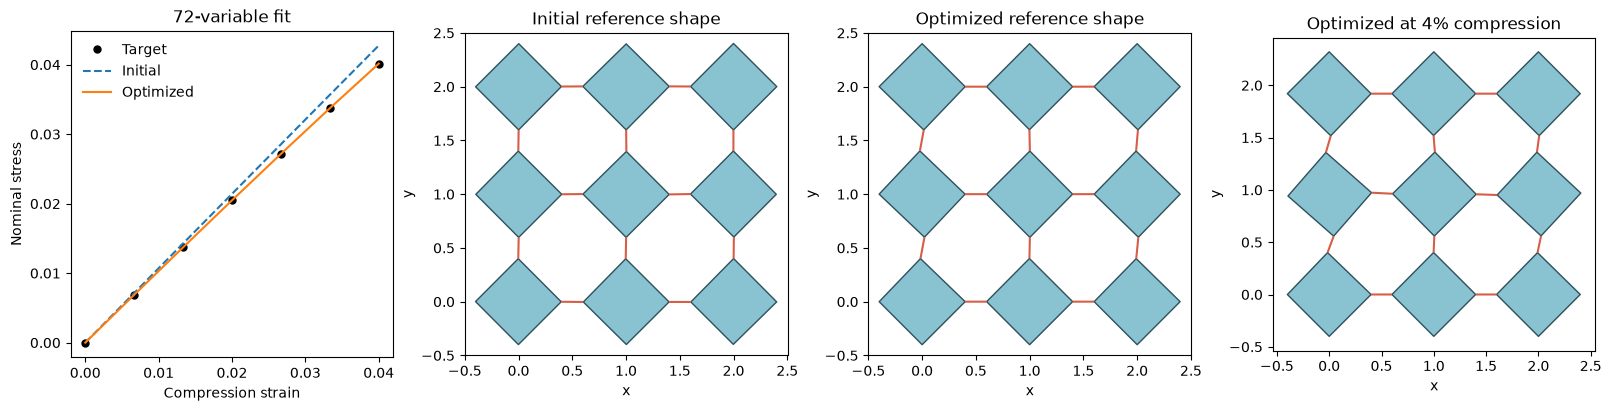

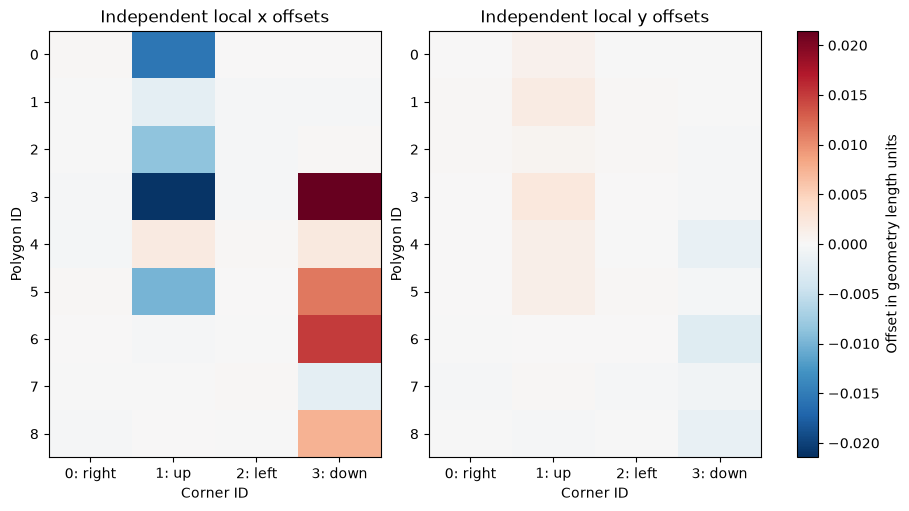

Polygon 4: each row is one corner; columns are x and y
[[-0.00034218  0.00013085]
 [ 0.00197089  0.00118167]
 [ 0.00020375 -0.00011137]
 [ 0.00203198 -0.00154165]]


In [10]:
# Supply the shared plotting helper with the explicitly constructed objects above.
plotting_problem = SimpleNamespace(
    geometry=geometry,
    initialize_design=initialize_design,
    initial_parameters=initial_parameters,
    simulate=simulate,
    strains=strains,
    target_stress=target_stress,
    measure_stress=measure_stress,
)
comparison_figure = plot_result(plotting_problem, result)
plt.show()

offsets_array = np.asarray(optimized_offsets)
color_limit = max(float(np.max(np.abs(offsets_array))), 1e-12)  # Common scale for x and y.
offset_figure, axes = plt.subplots(1, 2, figsize=(9, 5), layout="constrained")
for coordinate, ax in enumerate(axes):
    image = ax.imshow(
        offsets_array[:, :, coordinate],
        cmap="RdBu_r",
        vmin=-color_limit,
        vmax=color_limit,
        aspect="auto",
    )
    ax.set(
        title=f"Independent local {'x' if coordinate == 0 else 'y'} offsets",
        xlabel="Corner ID",
        ylabel="Polygon ID",
        xticks=range(4),
        xticklabels=["0: right", "1: up", "2: left", "3: down"],
        yticks=range(geometry.n_polygons),
    )
offset_figure.colorbar(image, ax=axes, label="Offset in geometry length units")
plt.show()

print("Polygon 4: each row is one corner; columns are x and y")
print(offsets_array[4])  # Access one polygon without flattening away the meaning of the axes.

## 10. Save the full design and customize the study

The saved tensor contains every independent offset, along with the actual local
vertices, stresses, and mechanical states. Loading the `.npz` file does not require
pickle. For another grid size, change `nx, ny` and rerun from the geometry cell;
all parameter shapes and bounds are derived from the number of polygons.

- **Different supports:** change `boundary` before constructing the solver;
  see [tutorial 02](02_boundary_conditions.ipynb).
- **Different target or objective:** replace `target_stress` or `curve_loss`;
  see [tutorial 03](03_optimization_objectives.ipynb).
- **Stiffness design:** use explicitly passed material parameters as in
  [tutorial 04](04_optimize_spring_constants.ipynb); fixed literals here are not optimized.
- **Shape freedom:** change the per-coordinate bounds or penalty weight. There
  is no repeated pattern constraint in this example.
- **More informative identification:** add other loading cases or measured
  polygon motions. Good curve agreement alone does not establish a unique shape.

For a script run: `python examples/optimize_all_vertices.py --output outputs`.

In [11]:
output_directory = example_directory.parent / "outputs"
output_directory.mkdir(parents=True, exist_ok=True)
np.savez_compressed(
    output_directory / "all_vertices_notebook.npz",
    parameters=offsets_array,  # Full independent (n_polygons, 4, 2) tensor.
    initial_parameters=np.asarray(initial_parameters),
    vertices=np.asarray(optimized_reference.vertices),
    states=np.asarray(optimized_solution.states),
    strains=np.asarray(strains),
    target_stress=np.asarray(target_stress),
    optimized_stress=np.asarray(measure_stress(optimized_solution.states, optimized_reference)),
    loss_history=result.loss_history,
)
comparison_figure.savefig(output_directory / "all_vertices_notebook.png", dpi=160)
print("Saved to:", output_directory.resolve())

Saved to: /home/daniel/Documents/Postdoc/2DmetaOptimizer/rotating-polygons/outputs


## 11. Make a video of the optimized design

Pass the optimized **local vertices** together with the computed mechanical states.
The function fixes the camera limits for the whole trajectory. The seven states
below are equilibrium samples, so their playback speed has no physical meaning.
For smoother quasistatic playback, solve at more strain samples; the exporter
never invents intermediate equilibrium states.

This cell writes a GIF using Pillow. Change the filename to `.mp4` to use ffmpeg;
if ffmpeg is unavailable, the default fallback returns a `.gif` path. Use
`fallback_to_gif=False` to require MP4. For long Verlet trajectories, increase
`stride` to export every nth saved state. See [make_video.py](make_video.py) for
a complete standalone example.

Video saved to: /home/daniel/Documents/Postdoc/2DmetaOptimizer/rotating-polygons/outputs/optimized_all_vertices.gif


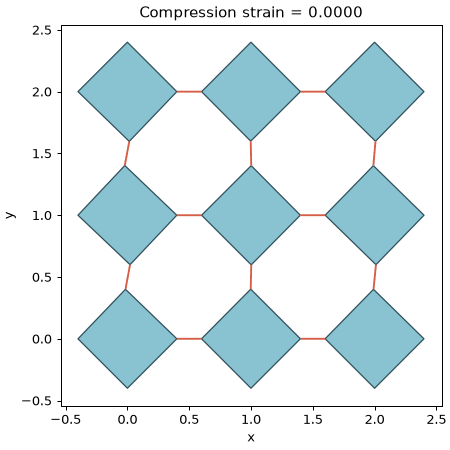

In [12]:
from rotating_polygons import save_video
from IPython.display import Image, display

video_path = save_video(
    geometry,
    optimized_solution.states,  # Translations and angles at each solved strain.
    output_directory / "optimized_all_vertices.gif",
    vertices=optimized_reference.vertices,  # Include every optimized corner offset.
    frame_labels=[f"Compression strain = {float(strain):.4f}" for strain in strains],
    fps=2,  # Two frames per second for this short quasistatic trajectory.
    stride=1,  # Keep all seven computed states.
    figsize=(5, 5),
    dpi=90,
)
print("Video saved to:", video_path.resolve())
display(Image(filename=str(video_path)))

## 12. Use NLopt for the same design problem

Install `python -m pip install -e ".[nlopt]"` from the repository root. Replace
the `minimize_design` call in section 8 with the following call. The 72-variable
map, objective, bounds, geometry constraints, and inner BFGS solver stay the same.
The wrapper supplies JAX derivatives and converts the constraint signs for NLopt.

```python
from rotating_polygons import minimize_design_nlopt

result = minimize_design_nlopt(
    loss,
    initial_parameters,
    bounds=bounds,
    constraints=[constraint],
    algorithm="slsqp",  # Select "mma" for NLopt's moving-asymptotes optimizer.
    maxeval=300,  # Counts objective evaluations, not design iterations.
    ftol_rel=1e-8,
    xtol_rel=1e-7,
    constraint_tol=1e-8,
)
if not result.success:
    raise RuntimeError(result.message)
```

Then rerun the postprocessing cells with this `result`. The returned
`result.parameters` has the same `(9, 4, 2)` shape. Evaluation/time limits report
`success=False`; feasibility alone does not establish convergence.

The executable [NLopt example](optimize_with_nlopt.py) performs an end-to-end fit
and checks the final stress error, constraints, and equilibrium residuals.
Its evaluation history can include rejected trial designs, so it need not decrease
monotonically.